<a href="https://colab.research.google.com/github/saheli56/Brain_Tumor_Detection_MRI/blob/main/Brain_Tumor_Detection_MRI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.11.0+cpu | device: cpu


In [ ]:
import kagglehub

dataset_path = Path(
    kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")
)
print("Dataset location:", dataset_path)
print("Contents:", sorted(p.name for p in dataset_path.iterdir()))

100%|██████████| 15.1M/15.1M [00:00<00:00, 54.7MB/s]

Extracting files...


Dataset location: /root/.cache/kagglehub/datasets/navoneel/brain-mri-images-for-brain-tumor-detection/versions/1
Contents: ['brain_tumor_dataset', 'no', 'yes']


In [ ]:
path_files_yes = sorted((dataset_path / "yes").glob("*"))
path_files_no = sorted((dataset_path / "no").glob("*"))

path_files = path_files_yes + path_files_no
labels = [1] * len(path_files_yes) + [0] * len(path_files_no)

print(f"Tumor    (1): {len(path_files_yes):>3} images")
print(f"No tumor (0): {len(path_files_no):>3} images")
print(f"Total       : {len(path_files):>3} images")

Tumor    (1): 155 images
No tumor (0):  98 images
Total       : 253 images


In [ ]:
modes = Counter()
widths, heights = [], []

for file in path_files:
    with Image.open(file) as img:
        modes[img.mode] += 1
        widths.append(img.width)
        heights.append(img.height)

print("Colour modes:", dict(modes))
print(f"Width  : min={min(widths):>5}  max={max(widths):>5}")
print(f"Height : min={min(heights):>5}  max={max(heights):>5}")

Colour modes: {'RGB': 217, 'L': 30, 'RGBA': 5, 'P': 1}
Width  : min=  150  max= 1920
Height : min=  168  max= 1427


In [ ]:
class BrainMRITumorDataset(Dataset):
    """Brain MRI images with a binary tumor label (1 = tumor, 0 = no tumor)."""

    def __init__(
        self,
        file_list: list[Path],
        labels: list[int],
        transform: transforms.Compose | None = None,
    ):
        self.file_list: list[Path] = file_list
        self.labels: list[int] = labels
        self.transform: transforms.Compose | None = transform

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor]:
        # convert("RGB") normalises grayscale/RGBA/palette images to 3 channels
        img = Image.open(self.file_list[idx]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)

        # int64 is what CrossEntropyLoss expects for class indices
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

    def __len__(self) -> int:
        return len(self.labels)


In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    path_files,
    labels,
    train_size=0.6,
    random_state=SEED,
    shuffle=True,
    stratify=labels,
)

# split the remaining 40% evenly into validation and test (20% / 20%)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    train_size=0.5,
    random_state=SEED,
    shuffle=True,
    stratify=y_temp,
)

In [ ]:
def print_split_summary(splits: dict[str, list[int]]) -> None:
    """Print size and class balance for each split, plus a total row."""
    total = sum(len(y) for y in splits.values())
    header = (
        f"{'Split':<12}{'Total':>8}{'Tumor (1)':>12}"
        f"{'No tumor (0)':>15}{'% of data':>12}{'% Tumor':>10}"
    )
    sep = "-" * len(header)

    def row(name: str, y: list[int]) -> str:
        tumor = sum(y)
        return (
            f"{name:<12}{len(y):>8}{tumor:>12}{len(y) - tumor:>15}"
            f"{len(y) / total * 100:>11.1f}%{tumor / len(y) * 100:>9.1f}%"
        )

    print(sep)
    print(f"{'Dataset Split Summary':^{len(header)}}")
    print(sep)
    print(header)
    print(sep)
    for name, y in splits.items():
        print(row(name, y))
    print(sep)
    print(row("Total", [label for y in splits.values() for label in y]))
    print(sep)


print_split_summary({"Train": y_train, "Validation": y_valid, "Test": y_test})

---------------------------------------------------------------------
                        Dataset Split Summary                        
---------------------------------------------------------------------
Split          Total   Tumor (1)   No tumor (0)   % of data   % Tumor
---------------------------------------------------------------------
Train            151          93             58       59.7%     61.6%
Validation        51          31             20       20.2%     60.8%
Test              51          31             20       20.2%     60.8%
---------------------------------------------------------------------
Total            253         155             98      100.0%     61.3%
---------------------------------------------------------------------


In [ ]:
from torchvision.transforms import (
    ColorJitter,
    Compose,
    RandomAffine,
    RandomHorizontalFlip,
    Resize,
    ToTensor,
)

IMAGE_SIZE = (150, 150)

train_transformer = Compose(
    [
        RandomHorizontalFlip(p=0.5),
        RandomAffine(
            degrees=8,
            translate=(0.05, 0.05),
            scale=(0.95, 1.05),
        ),
        ColorJitter(brightness=0.15, contrast=0.15),
        Resize(size=IMAGE_SIZE),
        ToTensor(),
    ]
)

# No randomness here - evaluation has to be reproducible.
eval_transformer = Compose(
    [
        Resize(size=IMAGE_SIZE),
        ToTensor(),
    ]
)

In [ ]:
BATCH_SIZE = 16
NUM_WORKERS = 0  # 0 keeps things simple and deterministic in a notebook

train_dataset = BrainMRITumorDataset(X_train, y_train, transform=train_transformer)
validation_dataset = BrainMRITumorDataset(X_valid, y_valid, transform=eval_transformer)
test_dataset = BrainMRITumorDataset(X_test, y_test, transform=eval_transformer)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS
)

for name, loader in [
    ("train", train_loader),
    ("validation", validation_loader),
    ("test", test_loader),
]:
    print(f"{name:<11} {len(loader.dataset):>3} samples in {len(loader):>2} batches")

train       151 samples in 10 batches
validation   51 samples in  4 batches
test         51 samples in  4 batches


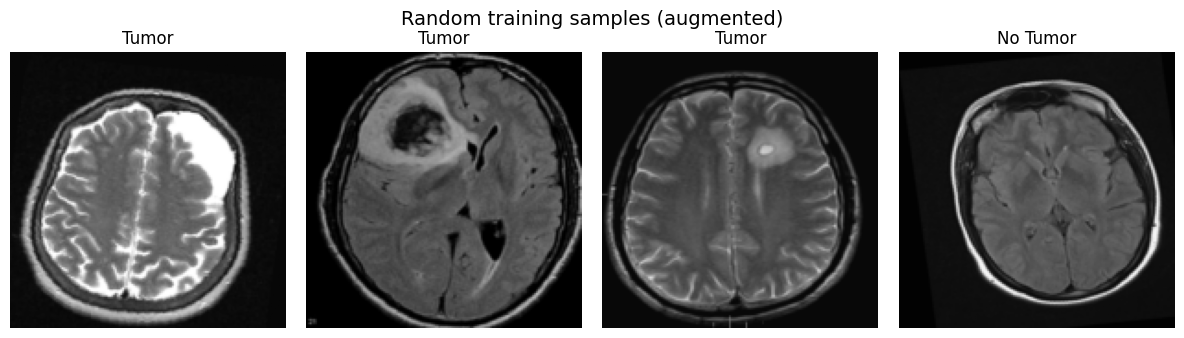

In [ ]:
def show_images(dataset: Dataset, indices: list[int], title: str) -> None:
    """Plot dataset samples in a single row with their labels as titles."""
    fig, axes = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3.4))
    fig.suptitle(title, fontsize=14)

    for ax, idx in zip(axes.flat, indices):
        img, label = dataset[idx]
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_title("Tumor" if label.item() == 1 else "No Tumor")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


sample_indices = random.sample(range(len(train_dataset)), 4)
show_images(train_dataset, sample_indices, "Random training samples (augmented)")


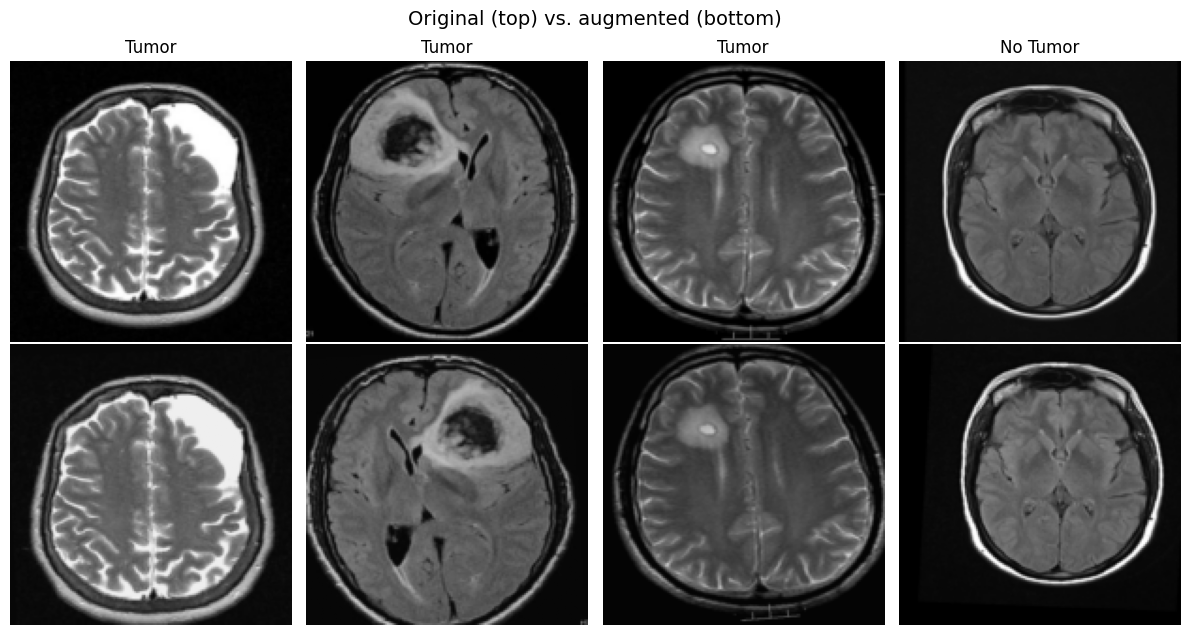

In [ ]:
# same underlying files as train_dataset, but with the deterministic pipeline
train_dataset_raw = BrainMRITumorDataset(X_train, y_train, transform=eval_transformer)

fig, axes = plt.subplots(2, len(sample_indices), figsize=(3 * len(sample_indices), 6.5))
fig.suptitle("Original (top) vs. augmented (bottom)", fontsize=14)

for column, idx in enumerate(sample_indices):
    original, label = train_dataset_raw[idx]
    augmented, _ = train_dataset[idx]

    axes[0, column].imshow(original.permute(1, 2, 0).clamp(0, 1))
    axes[0, column].set_title("Tumor" if label.item() == 1 else "No Tumor")
    axes[1, column].imshow(augmented.permute(1, 2, 0).clamp(0, 1))

    for row in (0, 1):
        axes[row, column].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import torch
import torch.nn as nn


class BrainMRIClassifier(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),
            nn.Dropout2d(p=0.3),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),
            nn.Dropout2d(p=0.3),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2),
            nn.Dropout2d(p=0.3),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(256, 2)

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        X = self.features(X)
        X = self.global_pool(X)
        X = torch.flatten(X, start_dim=1)
        return self.classifier(X)


model = BrainMRIClassifier()

test = torch.ones((16, 3, 150, 150))
shape_output = model(test).shape
print(shape_output)

model = BrainMRIClassifier().to(device)
print(model)

# Handy for checking shapes without running a real batch:
print(model(torch.randn(2, 3, 150, 150, device=device)).shape)

torch.Size([16, 2])
BrainMRIClassifier(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Dropout2d(p=0.3, inplace=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (7): Dropout2d(p=0.3, inplace=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (11): Dropout2d(p=0.3, inplace=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU()
  )
  (global_pool): AdaptiveAvgPool2d(output_size=1)
  (classifier): Linear(in_features=256, out_features=2, bias=True)
)
torch.Size([2, 2])


In [ ]:
import copy
import logging

import torch.nn as nn

logger = logging.getLogger("brain_mri_training")
if not logger.handlers:
    handler = logging.StreamHandler()
    handler.setFormatter(logging.Formatter("%(message)s"))
    logger.addHandler(handler)
logger.setLevel(logging.INFO)
logger.propagate = False


class_counts = torch.bincount(torch.tensor(y_train), minlength=2).float()
class_weights = class_counts.sum() / (2 * class_counts)
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
EPOCHS = 20
LEARNING_RATE = 1e-3

model = BrainMRIClassifier().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
logger.info(
    "Class counts: %s | loss weights: %s", class_counts.tolist(), class_weights.tolist()
)


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
) -> tuple[float, float]:
    """Train for one epoch and return (average loss, accuracy)."""
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == targets).sum().item()
        total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
) -> tuple[float, float]:
    """Evaluate without updating weights and return (average loss, accuracy)."""
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        outputs = model(images)
        loss = criterion(outputs, targets)

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == targets).sum().item()
        total_samples += batch_size

    return total_loss / total_samples, total_correct / total_samples


history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
}
best_validation_loss = float("inf")
best_model_state = None

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    validation_loss, validation_accuracy = evaluate(
        model, validation_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_model_state = copy.deepcopy(model.state_dict())

    logger.info(
        "epoch %2d/%d | train loss %.4f | train acc %.3f | "
        "val loss %.4f | val acc %.3f",
        epoch,
        EPOCHS,
        train_loss,
        train_accuracy,
        validation_loss,
        validation_accuracy,
    )

if best_model_state is not None:
    model.load_state_dict(best_model_state)
    logger.info(
        "Restored model from the epoch with the best validation loss: %.4f",
        best_validation_loss,
    )

Class counts: [58.0, 93.0] | loss weights: [1.3017241954803467, 0.8118279576301575]
epoch  1/20 | train loss 0.7002 | train acc 0.623 | val loss 0.6894 | val acc 0.627
epoch  2/20 | train loss 0.6972 | train acc 0.404 | val loss 0.6928 | val acc 0.392
epoch  3/20 | train loss 0.6954 | train acc 0.404 | val loss 0.6904 | val acc 0.510
epoch  4/20 | train loss 0.6877 | train acc 0.603 | val loss 0.6807 | val acc 0.608
epoch  5/20 | train loss 0.6765 | train acc 0.629 | val loss 0.6774 | val acc 0.608
epoch  6/20 | train loss 0.6837 | train acc 0.609 | val loss 0.6704 | val acc 0.745
epoch  7/20 | train loss 0.6832 | train acc 0.609 | val loss 0.6666 | val acc 0.745
epoch  8/20 | train loss 0.6763 | train acc 0.616 | val loss 0.6479 | val acc 0.686
epoch  9/20 | train loss 0.6687 | train acc 0.576 | val loss 0.6262 | val acc 0.745
epoch 10/20 | train loss 0.6426 | train acc 0.642 | val loss 0.5959 | val acc 0.765
epoch 11/20 | train loss 0.6611 | train acc 0.616 | val loss 0.6089 | val ac

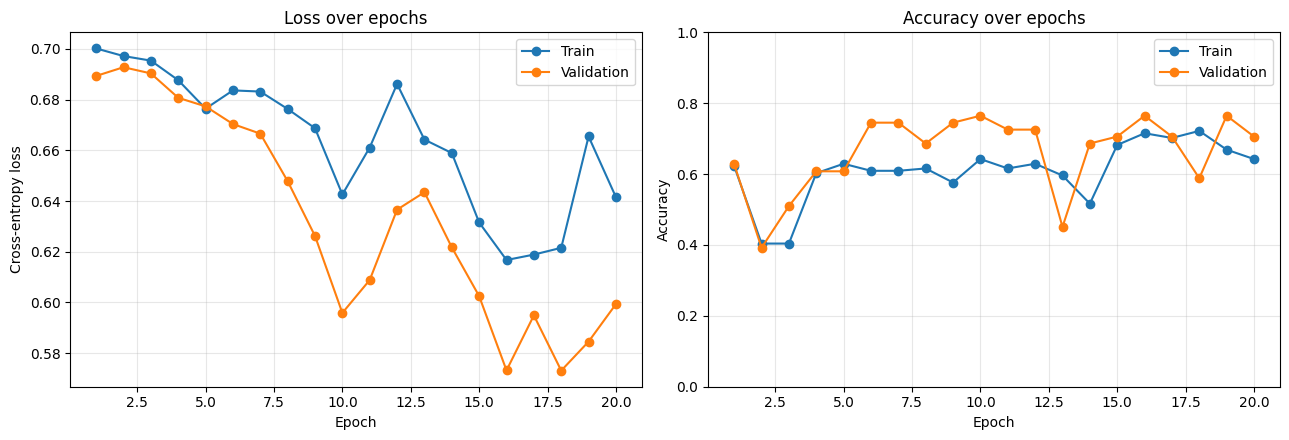

In [ ]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["validation_loss"], marker="o", label="Validation")
axes[0].set_title("Loss over epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, history["validation_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy over epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.0, 1.0)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix


@torch.no_grad()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> tuple[list[int], list[int]]:
    """Collect true labels and predicted labels for a data loader."""
    model.eval()
    all_targets = []
    all_predictions = []

    for images, targets in loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1).cpu().tolist()
        all_predictions.extend(predictions)
        all_targets.extend(targets.tolist())

    return all_targets, all_predictions


test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)
test_targets, test_predictions = collect_predictions(model, test_loader, device)
confusion = confusion_matrix(test_targets, test_predictions, labels=[0, 1])

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print("\nClassification report:")
print(
    classification_report(
        test_targets,
        test_predictions,
        labels=[0, 1],
        target_names=["No tumor", "Tumor"],
        zero_division=0,
    )
)

print("Confusion matrix (rows=true, columns=predicted):")
print("              predicted")
print("              no tumor  tumor")
print(f"true no tumor {confusion[0, 0]:>9} {confusion[0, 1]:>6}")
print(f"true tumor    {confusion[1, 0]:>9} {confusion[1, 1]:>6}")

Test loss: 0.5271
Test accuracy: 0.667

Classification report:
              precision    recall  f1-score   support

    No tumor       0.55      0.90      0.68        20
       Tumor       0.89      0.52      0.65        31

    accuracy                           0.67        51
   macro avg       0.72      0.71      0.67        51
weighted avg       0.75      0.67      0.66        51

Confusion matrix (rows=true, columns=predicted):
              predicted
              no tumor  tumor
true no tumor        18      2
true tumor           15     16


In [ ]:
@torch.no_grad()
def collect_tumor_scores(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> tuple[list[int], list[float]]:
    """Collect true labels and P(tumor) scores without updating the model."""
    model.eval()
    all_targets = []
    all_scores = []

    for images, targets in loader:
        probabilities = torch.softmax(model(images.to(device)), dim=1)
        all_scores.extend(probabilities[:, 1].cpu().tolist())
        all_targets.extend(targets.tolist())

    return all_targets, all_scores


validation_targets, validation_scores = collect_tumor_scores(
    model, validation_loader, device
)
validation_targets_array = np.asarray(validation_targets)
validation_scores_array = np.asarray(validation_scores)

positive_validation_scores = validation_scores_array[validation_targets_array == 1]
threshold = float(positive_validation_scores.min())

validation_predictions_threshold = (validation_scores_array >= threshold).astype(int)
validation_confusion = confusion_matrix(
    validation_targets,
    validation_predictions_threshold,
    labels=[0, 1],
)

threshold_test_targets, threshold_test_scores = collect_tumor_scores(
    model, test_loader, device
)
threshold_test_predictions = (np.asarray(threshold_test_scores) >= threshold).astype(
    int
)
threshold_confusion = confusion_matrix(
    threshold_test_targets,
    threshold_test_predictions,
    labels=[0, 1],
)

# Use threshold predictions for the report and the true-vs-predicted gallery.
test_targets = threshold_test_targets
test_predictions = threshold_test_predictions.tolist()
confusion = threshold_confusion

print(f"Threshold selected on validation data: {threshold:.3f}")
print(
    "Validation confusion matrix (rows=true, columns=predicted):\n",
    validation_confusion,
)
print("\nThreshold-based test classification report:")
print(
    classification_report(
        test_targets,
        test_predictions,
        labels=[0, 1],
        target_names=["No tumor", "Tumor"],
        zero_division=0,
    )
)
print("Threshold-based test confusion matrix (rows=true, columns=predicted):")
print(confusion)


Threshold selected on validation data: 0.157
Validation confusion matrix (rows=true, columns=predicted):
 [[ 5 15]
 [ 0 31]]

Threshold-based test classification report:
              precision    recall  f1-score   support

    No tumor       1.00      0.30      0.46        20
       Tumor       0.69      1.00      0.82        31

    accuracy                           0.73        51
   macro avg       0.84      0.65      0.64        51
weighted avg       0.81      0.73      0.68        51

Threshold-based test confusion matrix (rows=true, columns=predicted):
[[ 6 14]
 [ 0 31]]


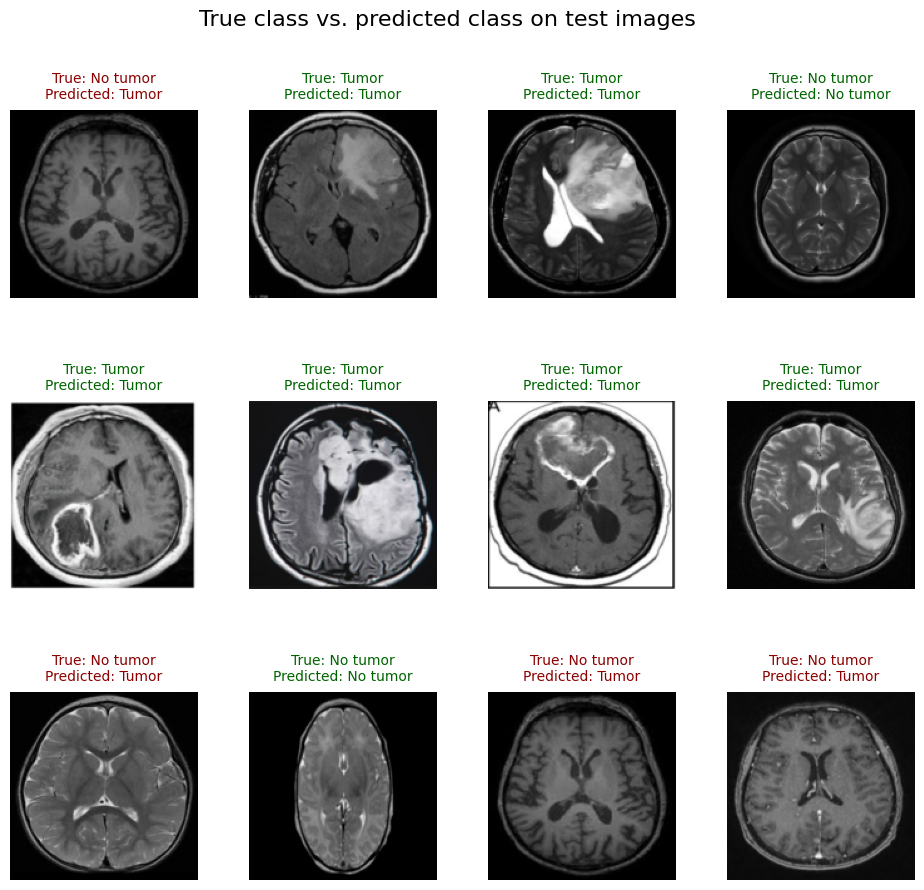

In [ ]:
label_names = {0: "No tumor", 1: "Tumor"}
rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(test_dataset), size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))
fig.suptitle("True class vs. predicted class on test images", fontsize=16)

for ax, index in zip(axes.flat, example_indices):
    image, _ = test_dataset[int(index)]
    true_label = int(test_targets[int(index)])
    predicted_label = int(test_predictions[int(index)])
    is_correct = true_label == predicted_label

    ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(
        f"True: {label_names[true_label]}\n"
        f"Predicted: {label_names[predicted_label]}",
        color="darkgreen" if is_correct else "darkred",
        fontsize=10,
        pad=8,
    )
    ax.axis("off")

fig.subplots_adjust(top=0.88, hspace=0.55, wspace=0.12)
plt.show()


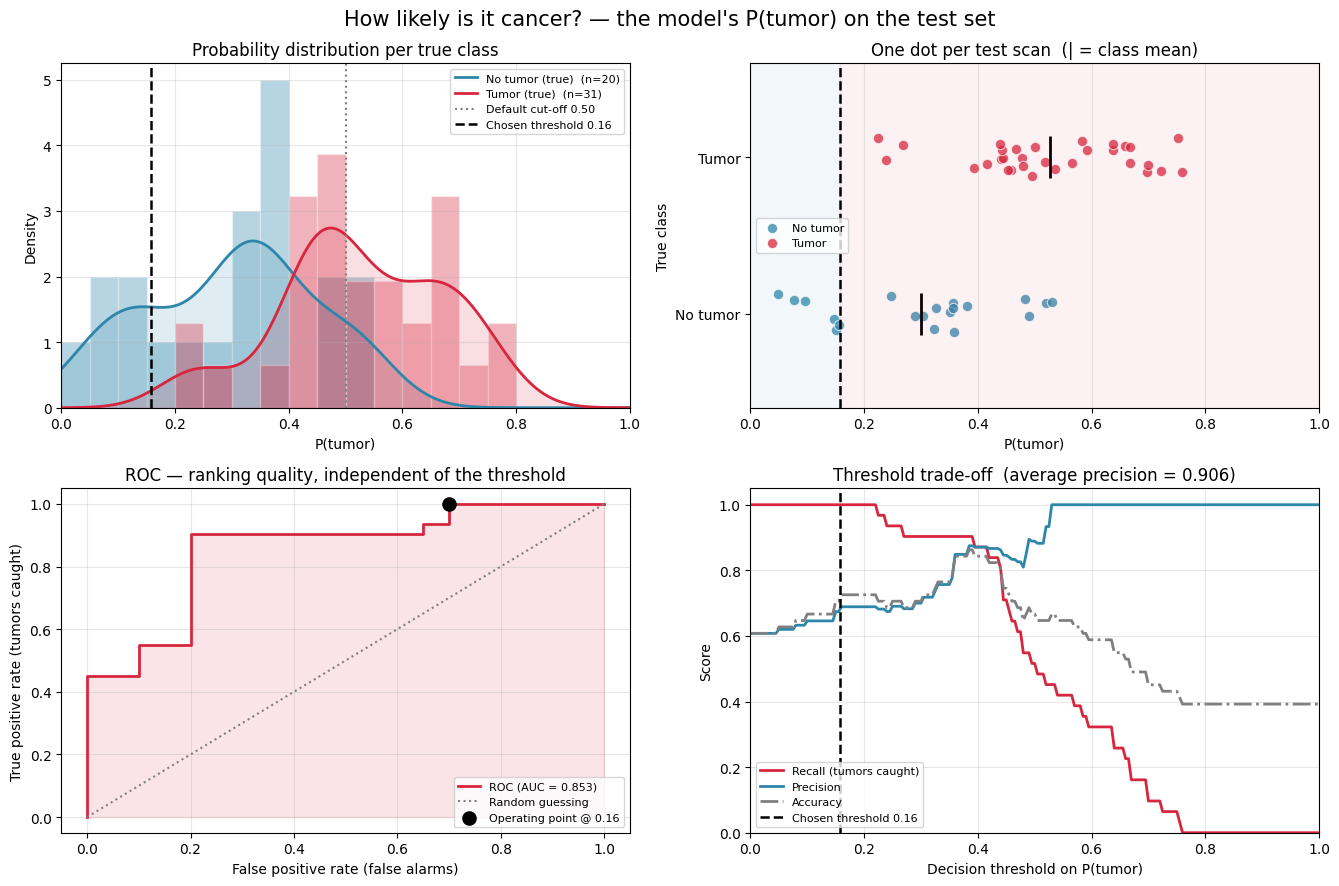

In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

NO_TUMOR_COLOR = "#2E86AB"
TUMOR_COLOR = "#D7263D"

test_scores_array = np.asarray(threshold_test_scores, dtype=float)
test_targets_array = np.asarray(threshold_test_targets, dtype=int)

scores_tumor = test_scores_array[test_targets_array == 1]
scores_no_tumor = test_scores_array[test_targets_array == 0]


def gaussian_kde(samples: np.ndarray, grid: np.ndarray) -> np.ndarray:
    """Gaussian kernel density estimate with a Silverman rule-of-thumb bandwidth."""
    samples = np.asarray(samples, dtype=float)
    if samples.size < 2:
        return np.zeros_like(grid)

    std = float(samples.std(ddof=1))
    iqr = float(np.subtract(*np.percentile(samples, [75, 25])))
    spread = min(std, iqr / 1.349) if iqr > 0 else std
    # the floor keeps the curve drawable even when all scores are nearly identical
    bandwidth = max(0.9 * spread * samples.size ** (-1 / 5), 0.02)

    z = (grid[:, None] - samples[None, :]) / bandwidth
    return np.exp(-0.5 * z**2).sum(axis=1) / (
        samples.size * bandwidth * np.sqrt(2 * np.pi)
    )


grid = np.linspace(0.0, 1.0, 400)
bins = np.linspace(0.0, 1.0, 21)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))
fig.suptitle(
    "How likely is it cancer? — the model's P(tumor) on the test set", fontsize=15
)

# 1. Distribution of the predicted probability, split by the true class
ax = axes[0, 0]
for scores, color, name in [
    (scores_no_tumor, NO_TUMOR_COLOR, "No tumor (true)"),
    (scores_tumor, TUMOR_COLOR, "Tumor (true)"),
]:
    ax.hist(scores, bins=bins, density=True, alpha=0.35, color=color, edgecolor="white")
    density = gaussian_kde(scores, grid)
    ax.plot(grid, density, color=color, linewidth=2, label=f"{name}  (n={scores.size})")
    ax.fill_between(grid, density, color=color, alpha=0.15)

ax.axvline(
    0.5, color="grey", linestyle=":", linewidth=1.5, label="Default cut-off 0.50"
)
ax.axvline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Chosen threshold {threshold:.2f}",
)
ax.set_title("Probability distribution per true class")
ax.set_xlabel("P(tumor)")
ax.set_ylabel("Density")
ax.set_xlim(0, 1)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# 2. Every single scan as a dot
ax = axes[0, 1]
jitter_rng = np.random.default_rng(SEED)
for class_value, color, name in [
    (0, NO_TUMOR_COLOR, "No tumor"),
    (1, TUMOR_COLOR, "Tumor"),
]:
    mask = test_targets_array == class_value
    ax.scatter(
        test_scores_array[mask],
        class_value + jitter_rng.uniform(-0.13, 0.13, size=int(mask.sum())),
        s=55,
        color=color,
        alpha=0.75,
        edgecolor="white",
        linewidth=0.8,
        label=name,
    )
    if mask.any():
        ax.scatter(
            test_scores_array[mask].mean(),
            class_value,
            marker="|",
            s=900,
            color="black",
            linewidth=2,
        )

ax.axvspan(0, threshold, color=NO_TUMOR_COLOR, alpha=0.06)
ax.axvspan(threshold, 1, color=TUMOR_COLOR, alpha=0.06)
ax.axvline(threshold, color="black", linestyle="--", linewidth=1.8)
ax.set_yticks([0, 1], ["No tumor", "Tumor"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlim(0, 1)
ax.set_title("One dot per test scan  (| = class mean)")
ax.set_xlabel("P(tumor)")
ax.set_ylabel("True class")
ax.legend(fontsize=8, loc="center left")
ax.grid(alpha=0.3, axis="x")

# 3. ROC curve - how well the probabilities rank the scans, whatever the threshold
ax = axes[1, 0]
false_positive_rate, true_positive_rate, roc_thresholds = roc_curve(
    test_targets_array, test_scores_array
)
roc_auc = roc_auc_score(test_targets_array, test_scores_array)

ax.plot(
    false_positive_rate,
    true_positive_rate,
    color=TUMOR_COLOR,
    linewidth=2,
    label=f"ROC (AUC = {roc_auc:.3f})",
)
ax.fill_between(false_positive_rate, true_positive_rate, alpha=0.12, color=TUMOR_COLOR)
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Random guessing")

operating_point = int(np.argmin(np.abs(roc_thresholds - threshold)))
ax.scatter(
    false_positive_rate[operating_point],
    true_positive_rate[operating_point],
    s=90,
    color="black",
    zorder=5,
    label=f"Operating point @ {threshold:.2f}",
)
ax.set_title("ROC — ranking quality, independent of the threshold")
ax.set_xlabel("False positive rate (false alarms)")
ax.set_ylabel("True positive rate (tumors caught)")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)

# 4. What every possible threshold would cost
ax = axes[1, 1]
candidate_thresholds = np.linspace(0.0, 1.0, 201)
predictions = test_scores_array[None, :] >= candidate_thresholds[:, None]
true_positives = (predictions & (test_targets_array == 1)).sum(axis=1)
predicted_positives = predictions.sum(axis=1)
positives = max(int((test_targets_array == 1).sum()), 1)

recall_curve = true_positives / positives
precision_curve = np.divide(
    true_positives,
    predicted_positives,
    out=np.ones(candidate_thresholds.size),
    where=predicted_positives > 0,
)
accuracy_curve = (predictions == (test_targets_array == 1)).mean(axis=1)
average_precision = average_precision_score(test_targets_array, test_scores_array)

ax.plot(
    candidate_thresholds,
    recall_curve,
    color=TUMOR_COLOR,
    linewidth=2,
    label="Recall (tumors caught)",
)
ax.plot(
    candidate_thresholds,
    precision_curve,
    color=NO_TUMOR_COLOR,
    linewidth=2,
    label="Precision",
)
ax.plot(
    candidate_thresholds,
    accuracy_curve,
    color="grey",
    linewidth=2,
    linestyle="-.",
    label="Accuracy",
)
ax.axvline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Chosen threshold {threshold:.2f}",
)
ax.set_title(f"Threshold trade-off  (average precision = {average_precision:.3f})")
ax.set_xlabel("Decision threshold on P(tumor)")
ax.set_ylabel("Score")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


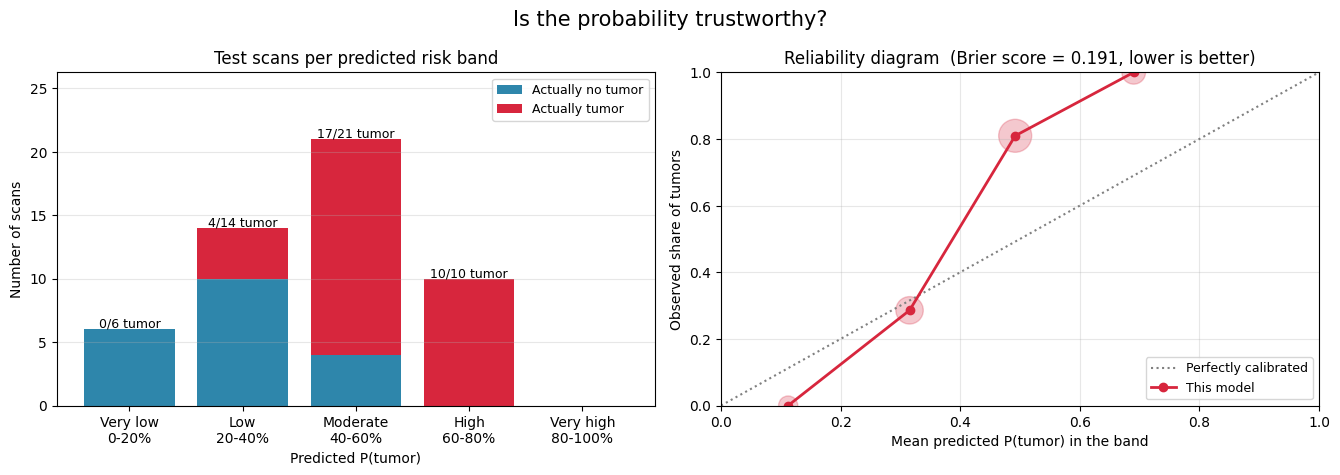

In [ ]:
RISK_EDGES = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
RISK_LABELS = [
    "Very low\n0-20%",
    "Low\n20-40%",
    "Moderate\n40-60%",
    "High\n60-80%",
    "Very high\n80-100%",
]

band_index = np.clip(
    np.digitize(test_scores_array, RISK_EDGES[1:-1]), 0, len(RISK_LABELS) - 1
)

band_tumor = np.array(
    [
        int(((band_index == b) & (test_targets_array == 1)).sum())
        for b in range(len(RISK_LABELS))
    ]
)
band_no_tumor = np.array(
    [
        int(((band_index == b) & (test_targets_array == 0)).sum())
        for b in range(len(RISK_LABELS))
    ]
)
band_total = band_tumor + band_no_tumor

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
fig.suptitle("Is the probability trustworthy?", fontsize=15)

# 1. How many scans land in each risk band, and what they really were
ax = axes[0]
positions = np.arange(len(RISK_LABELS))
ax.bar(positions, band_no_tumor, color=NO_TUMOR_COLOR, label="Actually no tumor")
ax.bar(
    positions,
    band_tumor,
    bottom=band_no_tumor,
    color=TUMOR_COLOR,
    label="Actually tumor",
)

for position, total, tumor in zip(positions, band_total, band_tumor):
    if total:
        ax.text(
            position, total + 0.15, f"{tumor}/{total} tumor", ha="center", fontsize=9
        )

ax.set_xticks(positions, RISK_LABELS)
ax.set_ylim(0, max(band_total.max(), 1) * 1.25)
ax.set_title("Test scans per predicted risk band")
ax.set_xlabel("Predicted P(tumor)")
ax.set_ylabel("Number of scans")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, axis="y")

# 2. Reliability: does "70% risk" really mean 7 out of 10?
ax = axes[1]
occupied = band_total > 0
mean_predicted = np.array(
    [
        test_scores_array[band_index == b].mean() if band_total[b] else np.nan
        for b in range(len(RISK_LABELS))
    ]
)
observed_rate = np.divide(
    band_tumor, band_total, out=np.full(len(RISK_LABELS), np.nan), where=band_total > 0
)

ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="Perfectly calibrated")
ax.plot(
    mean_predicted[occupied],
    observed_rate[occupied],
    marker="o",
    color=TUMOR_COLOR,
    linewidth=2,
    label="This model",
)
ax.scatter(
    mean_predicted[occupied],
    observed_rate[occupied],
    s=40 + 25 * band_total[occupied],
    color=TUMOR_COLOR,
    alpha=0.25,
)

brier_score = float(np.mean((test_scores_array - test_targets_array) ** 2))
ax.set_title(f"Reliability diagram  (Brier score = {brier_score:.3f}, lower is better)")
ax.set_xlabel("Mean predicted P(tumor) in the band")
ax.set_ylabel("Observed share of tumors")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(fontsize=9, loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


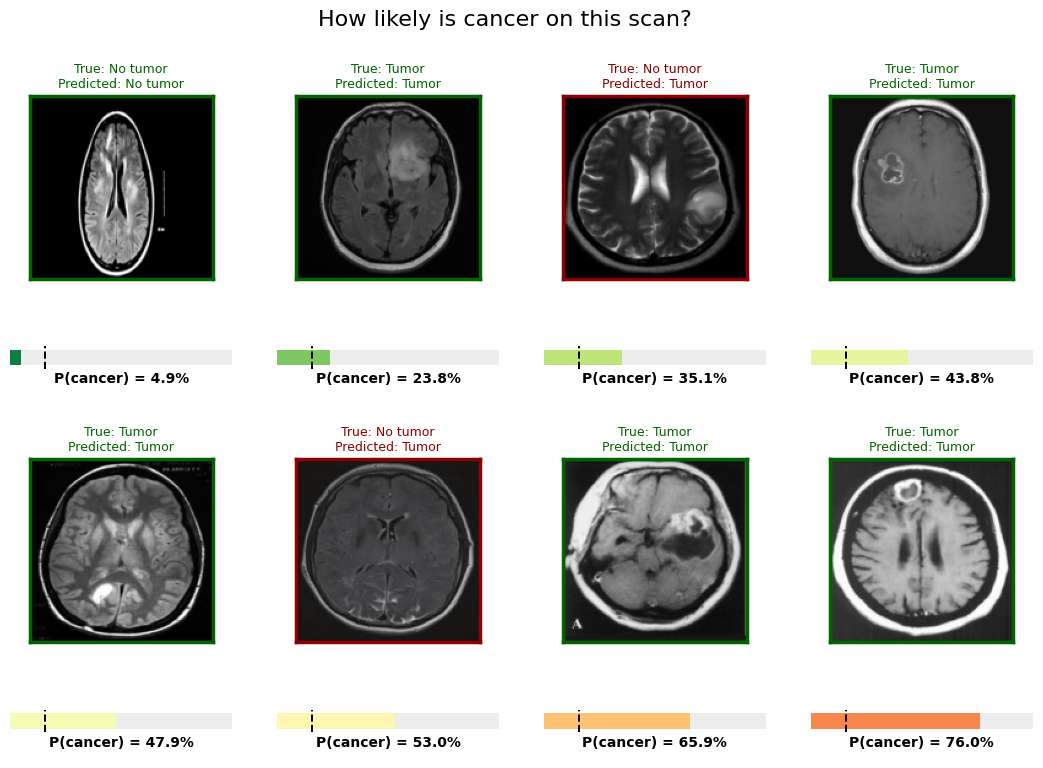

In [ ]:
from matplotlib import colormaps

RISK_CMAP = colormaps["RdYlGn_r"]

# eight scans spanning the whole probability range, from least to most suspicious
ranking = np.argsort(test_scores_array)
GALLERY_SIZE = min(8, ranking.size)
gallery_indices = ranking[
    np.linspace(0, ranking.size - 1, GALLERY_SIZE).round().astype(int)
]

columns = 4
rows = int(np.ceil(GALLERY_SIZE / columns))

fig, axes = plt.subplots(
    2 * rows,
    columns,
    figsize=(3.3 * columns, 4.3 * rows),
    gridspec_kw={"height_ratios": [1, 0.28] * rows},
    squeeze=False,
)
fig.suptitle("How likely is cancer on this scan?", fontsize=16)

for slot in range(rows * columns):
    image_ax = axes[2 * (slot // columns), slot % columns]
    bar_ax = axes[2 * (slot // columns) + 1, slot % columns]

    if slot >= GALLERY_SIZE:
        image_ax.axis("off")
        bar_ax.axis("off")
        continue

    index = int(gallery_indices[slot])
    image, _ = test_dataset[index]
    probability = float(test_scores_array[index])
    true_label = int(test_targets_array[index])
    predicted_label = int(probability >= threshold)
    is_correct = predicted_label == true_label
    outline = "darkgreen" if is_correct else "darkred"

    image_ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    image_ax.set_xticks([])
    image_ax.set_yticks([])
    for spine in image_ax.spines.values():
        spine.set_edgecolor(outline)
        spine.set_linewidth(2.5)
    image_ax.set_title(
        f"True: {label_names[true_label]}\nPredicted: {label_names[predicted_label]}",
        color=outline,
        fontsize=9,
        pad=6,
    )

    bar_ax.barh(0, 1.0, color="#EDEDED", height=0.55)
    bar_ax.barh(0, probability, color=RISK_CMAP(probability), height=0.55)
    bar_ax.plot(
        [threshold, threshold],
        [-0.4, 0.4],
        color="black",
        linestyle="--",
        linewidth=1.4,
    )
    bar_ax.text(
        0.5,
        -0.75,
        f"P(cancer) = {probability * 100:.1f}%",
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
    )
    bar_ax.set_xlim(0, 1)
    bar_ax.set_ylim(-1.3, 0.5)
    bar_ax.set_yticks([])
    bar_ax.set_xticks([])
    for spine in bar_ax.spines.values():
        spine.set_visible(False)

fig.subplots_adjust(top=0.88, hspace=0.55, wspace=0.2)
plt.show()

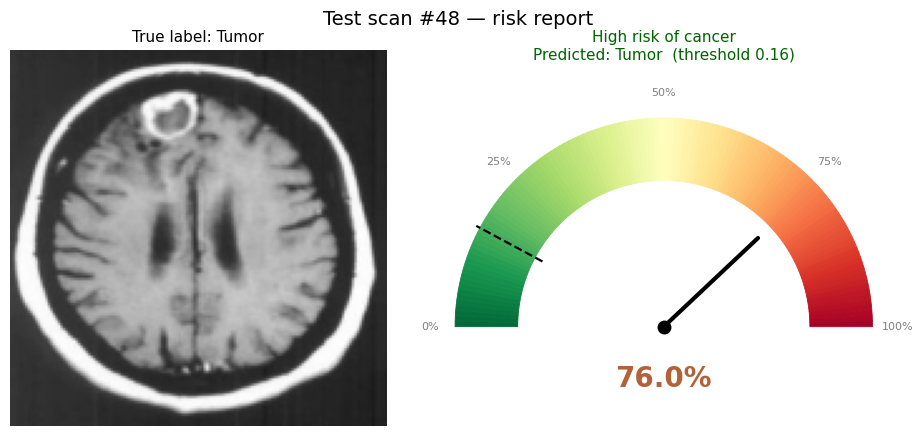

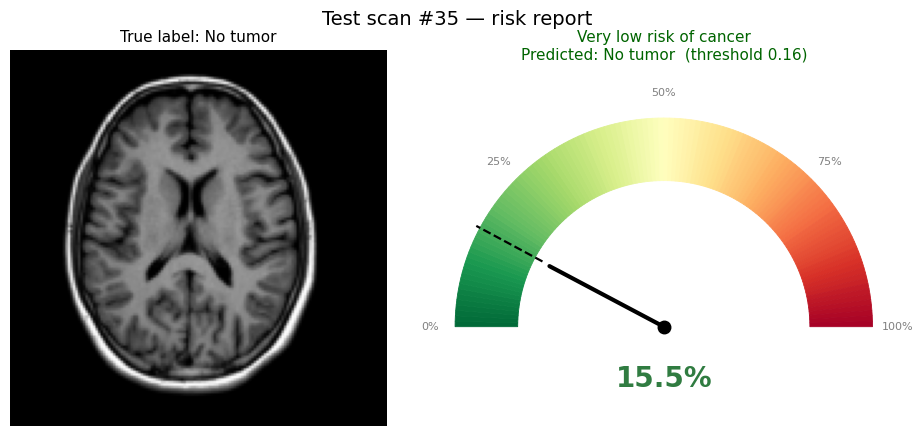

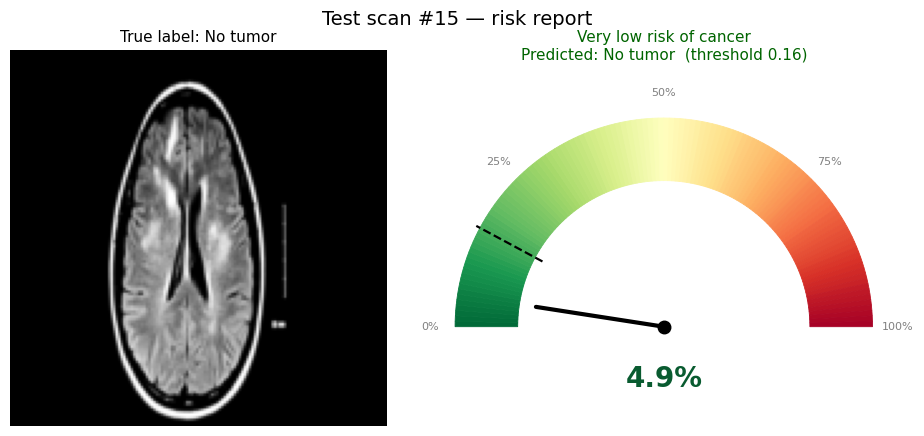

In [ ]:
from matplotlib.patches import Wedge


def draw_risk_gauge(ax: plt.Axes, probability: float, cut_off: float) -> None:
    """Draw a half-circle gauge: 0% risk on the left, 100% on the right."""
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-0.35, 1.2)

    # the coloured arc, painted as many thin wedges so it looks like a gradient
    steps = 120
    for step in range(steps):
        start, end = step / steps, (step + 1) / steps
        ax.add_patch(
            Wedge(
                (0, 0),
                1.0,
                180 * (1 - end),
                180 * (1 - start),
                width=0.3,
                facecolor=RISK_CMAP((start + end) / 2),
                edgecolor=RISK_CMAP((start + end) / 2),
                linewidth=0.6,
            )
        )

    for tick in (0.0, 0.25, 0.5, 0.75, 1.0):
        angle = np.pi * (1 - tick)
        ax.text(
            1.12 * np.cos(angle),
            1.12 * np.sin(angle),
            f"{tick * 100:.0f}%",
            ha="center",
            va="center",
            fontsize=8,
            color="grey",
        )

    cut_off_angle = np.pi * (1 - cut_off)
    ax.plot(
        [0.66 * np.cos(cut_off_angle), 1.02 * np.cos(cut_off_angle)],
        [0.66 * np.sin(cut_off_angle), 1.02 * np.sin(cut_off_angle)],
        color="black",
        linestyle="--",
        linewidth=1.6,
    )

    needle_angle = np.pi * (1 - probability)
    ax.plot(
        [0, 0.62 * np.cos(needle_angle)],
        [0, 0.62 * np.sin(needle_angle)],
        color="black",
        linewidth=3,
        solid_capstyle="round",
    )
    ax.plot(0, 0, marker="o", markersize=9, color="black")
    ax.text(
        0,
        -0.25,
        f"{probability * 100:.1f}%",
        ha="center",
        va="center",
        fontsize=20,
        fontweight="bold",
        # darkened so that even the pale yellow mid-range stays readable
        color=tuple(0.72 * channel for channel in RISK_CMAP(probability)[:3]),
    )


def risk_band(probability: float) -> str:
    """Turn a probability into a plain-language risk band."""
    band = int(
        np.clip(np.digitize(probability, RISK_EDGES[1:-1]), 0, len(RISK_LABELS) - 1)
    )
    return RISK_LABELS[band].split("\n")[0]


def show_risk_report(index: int) -> None:
    """Show one test scan next to a gauge of its predicted cancer probability."""
    image, _ = test_dataset[int(index)]
    probability = float(test_scores_array[int(index)])
    true_label = int(test_targets_array[int(index)])
    predicted_label = int(probability >= threshold)

    fig, (image_ax, gauge_ax) = plt.subplots(
        1, 2, figsize=(9.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]}
    )
    fig.suptitle(f"Test scan #{int(index)} — risk report", fontsize=14)

    image_ax.imshow(image.permute(1, 2, 0).clamp(0, 1))
    image_ax.axis("off")
    image_ax.set_title(f"True label: {label_names[true_label]}", fontsize=11)

    draw_risk_gauge(gauge_ax, probability, threshold)
    gauge_ax.set_title(
        f"{risk_band(probability)} risk of cancer\n"
        f"Predicted: {label_names[predicted_label]}  "
        f"(threshold {threshold:.2f})",
        fontsize=11,
        pad=12,
        color="darkgreen" if predicted_label == true_label else "darkred",
    )

    plt.tight_layout()
    plt.show()


most_suspicious = int(np.argmax(test_scores_array))
least_suspicious = int(np.argmin(test_scores_array))
most_uncertain = int(np.argmin(np.abs(test_scores_array - threshold)))

for index in (most_suspicious, most_uncertain, least_suspicious):
    show_risk_report(index)